# 02 · Exploración temporal de los indicadores

**Objetivo.** Antes de ajustar modelos, este notebook describe cómo evoluciona el **sentimiento**, el indicador de H1, entre 2016 y 2026: tendencia, picos, estacionalidad, autocorrelación y estacionariedad. También compara los periodos de Gobierno y de oposición de cada partido.

Todo lo que hay aquí es **descriptivo**. La elección de los modelos (órdenes ARIMA y diferenciación) se hará en el notebook 03, usando solo el tramo de entrenamiento para no mirar los datos de test.

**Entradas:**
- `data/panel_partido_mes.csv` (notebook 01): sentimiento mensual por partido y variable `gobierno`.
- `../corpus-indicators/data/processed/monthly.csv` (Entrega 2): sentimiento mensual global y proporción de tópicos.

> H1: las familias políticas presentan sentimiento más negativo en la oposición que en el Gobierno (2016–2026).

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
E2 = ROOT.parent / "corpus-indicators" / "data" / "processed"
DATA, RESULTS = ROOT / "data", ROOT / "results"
PARTIDOS = ["PP", "PSOE", "Podemos-UP-Sumar", "VOX", "Cs"]
COLOR = {"PP": "#1d5fa8", "PSOE": "#d62728", "Podemos-UP-Sumar": "#6a3d9a", "VOX": "#4daf4a", "Cs": "#ff7f0e"}

panel = pd.read_csv(DATA / "panel_partido_mes.csv")
panel["fecha"] = pd.to_datetime(panel.month)
glob = pd.read_csv(E2 / "monthly.csv")
glob["fecha"] = pd.to_datetime(glob.month)
glob = glob.set_index("fecha").asfreq("MS")      # frecuencia mensual explícita
interv = pd.read_parquet(DATA / "intervenciones_gobierno.parquet")
INICIO_LEG = interv.groupby("legislature").date.min()   # primera sesión de cada legislatura en la muestra
INICIO_LEG

legislature
12   2016-08-30
13   2019-07-22
14   2020-01-04
15   2023-09-19
Name: date, dtype: datetime64[ns]

## 1. Las series y sus huecos

La serie global tiene 122 meses de calendario. Los meses sin intervenciones se **mantienen vacíos**: no son ceros ni se interpolan.

In [2]:
vacios = glob.index[glob.n_turns == 0]
print(f"Meses de calendario: {len(glob)} · con datos: {(glob.n_turns > 0).sum()} · vacíos: {len(vacios)}")
print("Meses vacíos:", ", ".join(vacios.strftime("%Y-%m")))
print("\nVacíos por mes del año:")
print(pd.Series(vacios.month).value_counts().sort_index().rename(lambda m: f"mes {m:02d}").to_string())

Meses de calendario: 122 · con datos: 104 · vacíos: 18
Meses vacíos: 2018-01, 2018-08, 2019-03, 2019-04, 2019-05, 2019-06, 2019-10, 2019-11, 2019-12, 2020-08, 2021-08, 2023-06, 2023-07, 2023-08, 2023-10, 2024-08, 2025-08, 2026-08

Vacíos por mes del año:
fecha
mes 01    1
mes 03    1
mes 04    1
mes 05    1
mes 06    2
mes 07    1
mes 08    7
mes 10    2
mes 11    1
mes 12    1


Hay dos tipos de hueco:
- **Estructurales:** **agosto**, mes sin sesiones plenarias, falta todos los años.
- **Políticos:** los periodos de disolución de las Cortes y de nueva constitución en torno a las elecciones de **2019** (abril y noviembre) y **2023** (julio).

Ninguno es un error de datos, así que no tiene sentido rellenarlos. SARIMAX trabaja directamente con meses vacíos (filtro de Kalman), y eso es lo que se usará en el notebook 03.

**El ruido de cada mes depende de cuántas intervenciones tenga.** Se calcula el error estándar de la media mensual (desviación típica / √n) a partir de las intervenciones.

In [3]:
ee = (interv.dropna(subset=["sentiment"]).groupby(["month", "party"]).sentiment
      .agg(n="size", sd="std").assign(ee=lambda d: d.sd / np.sqrt(d.n)))
print("Desviación típica del sentimiento entre intervenciones:", round(interv.sentiment.std(), 3))
ee.groupby("party")[["n", "ee"]].median().round(3).rename(
    columns={"n": "mediana_intervenciones_mes", "ee": "mediana_error_estandar"})

Desviación típica del sentimiento entre intervenciones: 0.29


,mediana_intervenciones_mes,mediana_error_estandar
party,,
Cs,15.5,0.059
PP,35.0,0.039
PSOE,28.5,0.050
Podemos-UP-Sumar,17.0,0.054
VOX,21.5,0.047


El sentimiento varía mucho de una intervención a otra (desviación típica ≈ 0,29). Con unas 15–35 intervenciones al mes, la media mensual de un partido tiene un error estándar de unas **0,04–0,06** unidades. Por tanto, oscilaciones de ±0,1 entre dos meses consecutivos pueden deberse solo al azar de la muestra. Por eso conviene mirar medias móviles y no meses sueltos, y los modelos tendrán bastante ruido.

## 2. Evolución global

Sentimiento medio mensual de todas las intervenciones, con la media móvil de 6 meses y el inicio de cada legislatura.

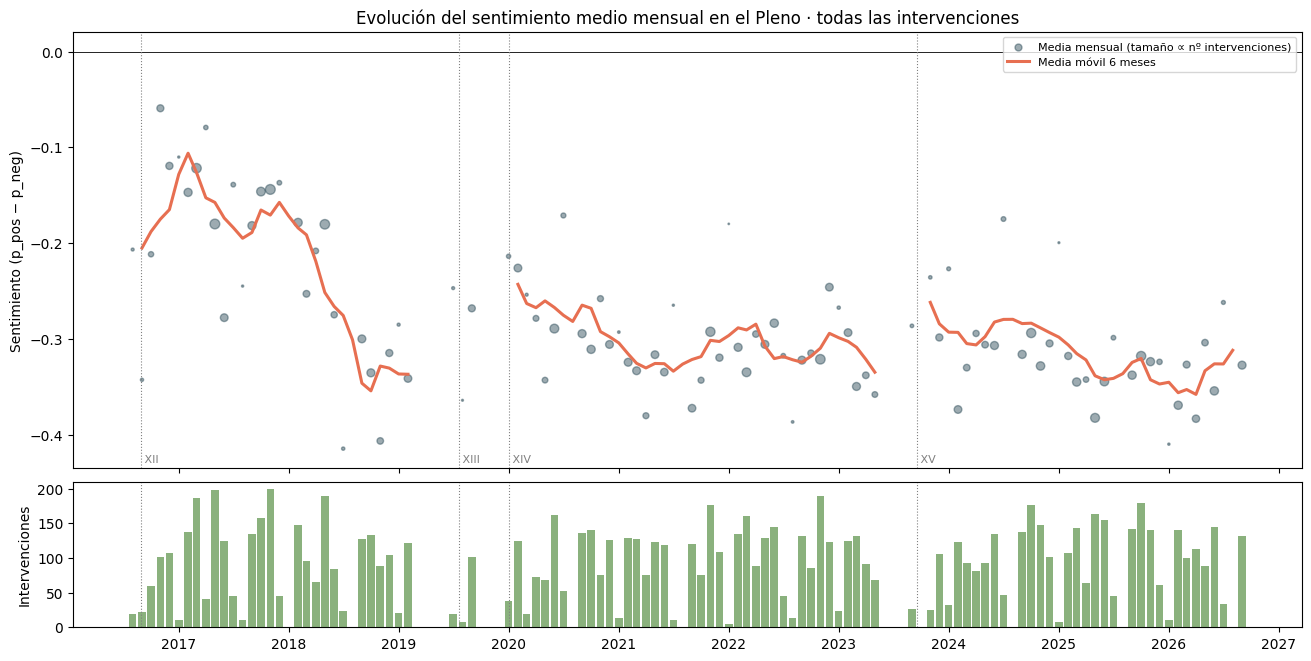

In [4]:
def media_movil(s, w=6, minimo=4):
    """Media móvil de calendario: ignora los meses vacíos y exige al menos `minimo` meses con dato."""
    return s.rolling(w, min_periods=minimo, center=True).mean()

def marcar_legislaturas(ax, y=None):
    for leg, fecha in INICIO_LEG.items():
        ax.axvline(fecha, color="gray", ls=":", lw=.8)
        if y is not None:
            ax.text(fecha, y, f" {['XII','XIII','XIV','XV'][[12,13,14,15].index(leg)]}", fontsize=8,
                    color="gray", transform=ax.get_xaxis_transform(), va="bottom")

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True, height_ratios=[3, 1], layout="constrained")
ax = axes[0]
ax.scatter(glob.index, glob.sentiment, s=glob.n_turns / 4, color="#264653", alpha=.45, label="Media mensual (tamaño ∝ nº intervenciones)")
ax.plot(glob.index, media_movil(glob.sentiment), color="#e76f51", lw=2.2, label="Media móvil 6 meses")
ax.axhline(0, color="black", lw=.6)
marcar_legislaturas(ax, y=0.01)
ax.set_ylabel("Sentimiento (p_pos − p_neg)")
ax.set_title("Evolución del sentimiento medio mensual en el Pleno · todas las intervenciones")
ax.legend(loc="upper right", fontsize=8)
axes[1].bar(glob.index, glob.n_turns, width=25, color="#8ab17d")
axes[1].set_ylabel("Intervenciones")
marcar_legislaturas(axes[1])
axes[1].xaxis.set_major_locator(mdates.YearLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.savefig(RESULTS / "02_sentimiento_global.png", dpi=160)
plt.show()

**Tendencia:** se ajusta una recta del sentimiento mensual sobre el tiempo (en años), para medir la caída que ya se veía por legislaturas en la Entrega 2. Es descriptiva y no corrige la autocorrelación: el error estándar de la pendiente estará subestimado.

In [5]:
obs = glob.dropna(subset=["sentiment"])
anios = (obs.index - obs.index[0]).days / 365.25
pendiente, ordenada = np.polyfit(anios, obs.sentiment, 1)
print(f"Pendiente: {pendiente:+.4f} por año  →  {pendiente * anios.max():+.3f} en {anios.max():.1f} años")
print(f"Sentimiento ajustado al inicio: {ordenada:.3f} · al final: {ordenada + pendiente * anios.max():.3f}")
pd.DataFrame({"legislatura": INICIO_LEG.index,
              "sentimiento_medio": [interv.loc[interv.legislature == l, "sentiment"].mean() for l in INICIO_LEG.index]}).round(3)

Pendiente: -0.0142 por año  →  -0.143 en 10.1 años
Sentimiento ajustado al inicio: -0.210 · al final: -0.353


,legislatura,sentimiento_medio
0,12,-0.208
1,13,-0.271
2,14,-0.308
3,15,-0.326


**Aviso de composición:** la media global depende de qué partidos hablan cada mes. Por ejemplo, desde 2020 entra VOX, que es el partido más negativo. Parte de la caída global puede deberse a la composición de la muestra y no a un cambio de tono de los mismos partidos. Por eso H1 se estudia partido a partido.

## 3. Evolución por partido y rol

Cada panel muestra la media mensual de un partido (puntos), su media móvil de 6 meses (línea) y, sombreados, los periodos en que **gobierna**. Si H1 es cierta, la línea debería estar más alta en las zonas sombreadas.

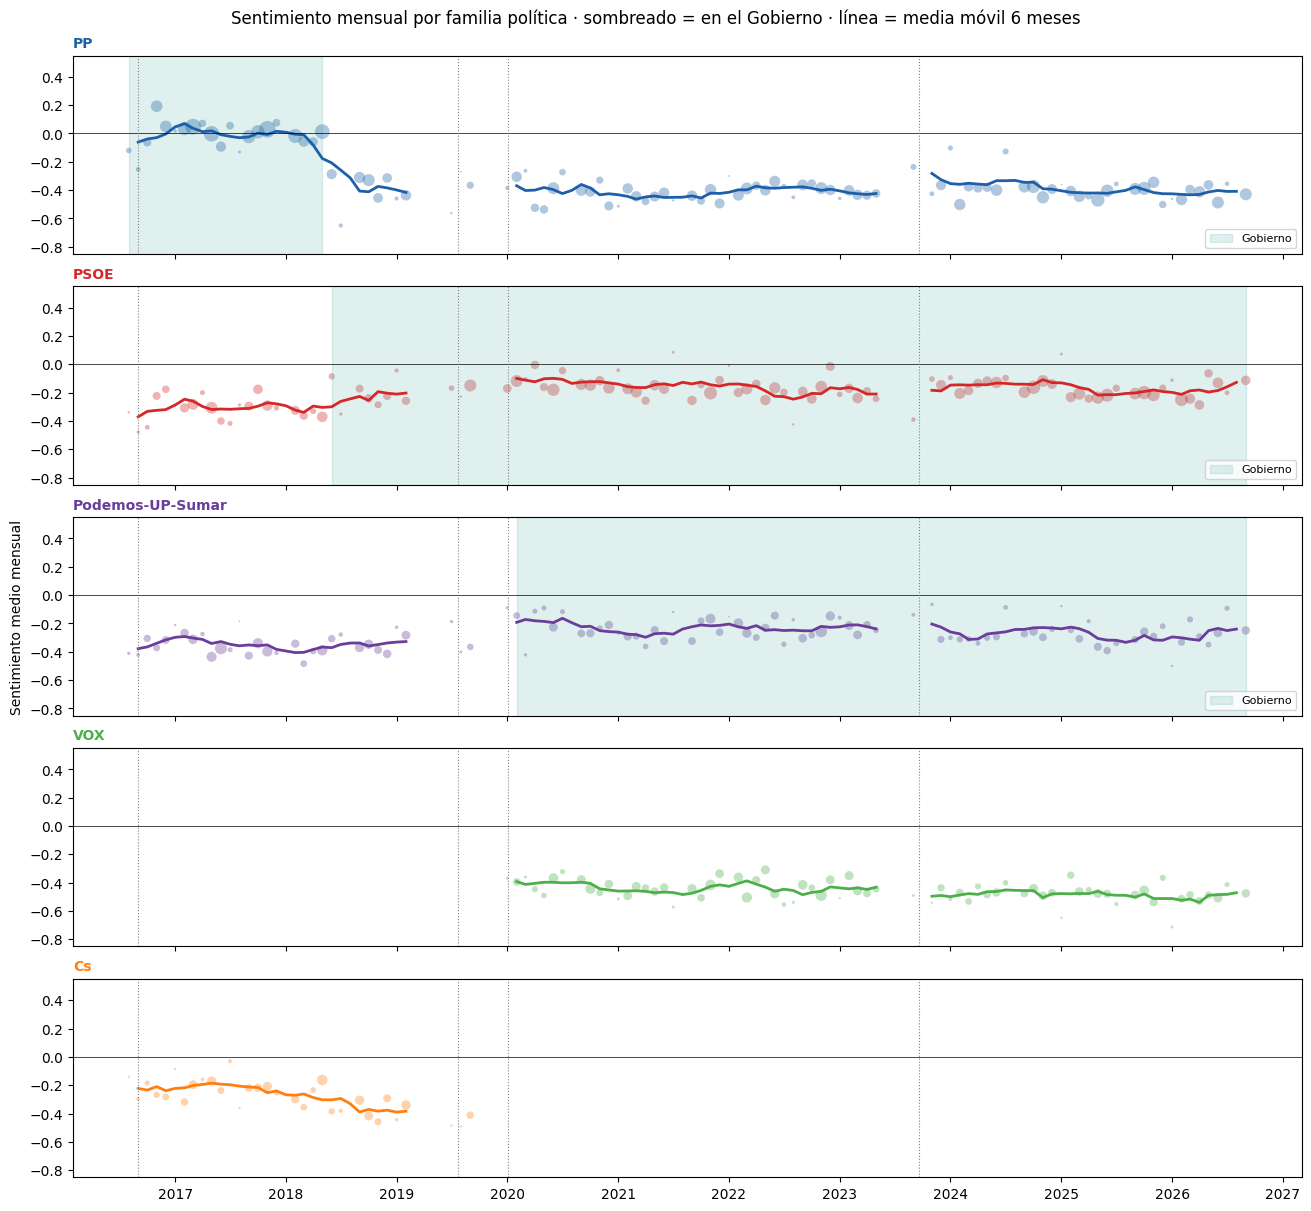

In [6]:
fig, axes = plt.subplots(len(PARTIDOS), 1, figsize=(13, 12), sharex=True, sharey=True, layout="constrained")
for ax, p in zip(axes, PARTIDOS):
    d = panel[panel.party == p].set_index("fecha").asfreq("MS")
    ax.scatter(d.index, d.sentiment, s=d.n_sentiment * 1.5, color=COLOR[p], alpha=.35, linewidths=0)
    ax.plot(d.index, media_movil(d.sentiment), color=COLOR[p], lw=2)
    gob = d.gobierno.eq(1)
    ax.fill_between(d.index, -1, 1, where=gob, step="mid", color="#2a9d8f", alpha=.15,
                    label="Gobierno" if gob.any() else None)
    ax.axhline(0, color="black", lw=.5)
    ax.set_ylim(-.85, .55)
    ax.set_title(p, loc="left", fontsize=10, color=COLOR[p], fontweight="bold")
    marcar_legislaturas(ax)
    if gob.any():
        ax.legend(loc="lower right", fontsize=8)
axes[2].set_ylabel("Sentimiento medio mensual")
axes[-1].xaxis.set_major_locator(mdates.YearLocator()); axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Sentimiento mensual por familia política · sombreado = en el Gobierno · línea = media móvil 6 meses")
fig.savefig(RESULTS / "02_sentimiento_por_partido.png", dpi=160)
plt.show()

**Nota de lectura:** la media móvil está centrada (usa 3 meses antes y 3 después), así que un cambio brusco aparece "suavizado" y parece empezar unos meses antes de ocurrir. Para fechar el cambio hay que mirar los puntos, no la línea.

## 4. Comparación de periodos en torno a los cambios de Gobierno

Se compara el sentimiento medio de los **12 meses anteriores y posteriores** a cada cambio de Gobierno, contando las intervenciones de cada ventana. Cada cambio tiene partidos que cambian de rol y partidos que no, que sirven como **referencia**: si estos también cambian, parte del cambio se debe al momento y no al rol.

- **Junio de 2018 (moción de censura):** el PP pasa del Gobierno a la oposición, el PSOE de la oposición al Gobierno, y Podemos y Cs siguen en la oposición (referencia).
- **Enero de 2020 (coalición):** Podemos pasa de la oposición al Gobierno, el PSOE sigue en el Gobierno y el PP sigue en la oposición (referencia). VOX no tiene datos antes de 2020 en la muestra.

Las ventanas se fijan **antes de mirar los resultados**, a 12 meses. Como el año 2019 tiene muchos meses vacíos, la ventana anterior a 2020 contiene menos datos.

In [7]:
eventos = {"Moción de censura (2-6-2018)": pd.Timestamp("2018-06-02"),
           "Gobierno de coalición (13-1-2020)": pd.Timestamp("2020-01-13")}
filas = []
for evento, f in eventos.items():
    antes = interv[(interv.date >= f - pd.DateOffset(months=12)) & (interv.date < f)]
    despues = interv[(interv.date >= f) & (interv.date < f + pd.DateOffset(months=12))]
    for p in PARTIDOS:
        a, b = antes[antes.party == p], despues[despues.party == p]
        if a.sentiment.count() < 20 or b.sentiment.count() < 20:
            continue
        rol_a = "Gob" if a.gobierno.mean() > .5 else "Opo"
        rol_b = "Gob" if b.gobierno.mean() > .5 else "Opo"
        filas.append({"evento": evento, "partido": p, "rol": f"{rol_a} → {rol_b}",
                      "n_antes": a.sentiment.count(), "sent_antes": a.sentiment.mean(),
                      "n_despues": b.sentiment.count(), "sent_despues": b.sentiment.mean(),
                      "cambio": b.sentiment.mean() - a.sentiment.mean()})
ventanas = pd.DataFrame(filas)
ventanas.to_csv(RESULTS / "02_ventanas_cambio_gobierno.csv", index=False)
ventanas.round(3)

,evento,partido,rol,n_antes,sent_antes,n_despues,sent_despues,cambio
0,Moción de censura (2-6-2018),PP,Gob → Opo,513,-0.005,245,-0.366,-0.361
1,Moción de censura (2-6-2018),PSOE,Opo → Gob,249,-0.314,132,-0.217,0.098
2,Moción de censura (2-6-2018),Podemos-UP-Sumar,Opo → Opo,252,-0.385,168,-0.346,0.040
3,Moción de censura (2-6-2018),Cs,Opo → Opo,194,-0.226,151,-0.362,-0.136
4,Gobierno de coalición (13-1-2020),PP,Opo → Opo,71,-0.418,285,-0.408,0.010
5,Gobierno de coalición (13-1-2020),PSOE,Gob → Gob,119,-0.174,340,-0.131,0.043
6,Gobierno de coalición (13-1-2020),Podemos-UP-Sumar,Opo → Gob,56,-0.290,153,-0.212,0.078


**Cómo leer la tabla:** H1 predice que el cambio sea **negativo** en Gob → Opo y **positivo** en Opo → Gob. El cambio de los partidos sin cambio de rol (Opo → Opo, Gob → Gob) mide la variación general del momento. La comparación justa es la diferencia entre ambos, al estilo de "diferencias en diferencias". Es solo descriptiva: no tiene en cuenta la autocorrelación ni los cambios en los temas debatidos.

## 5. Brecha PP − PSOE

Restar el sentimiento de los dos partidos cada mes elimina lo que les afecta a ambos por igual (tendencia general, temas del momento, clima político). Si H1 es cierta, la brecha debería ser **positiva antes de junio de 2018** (PP en el Gobierno) y **negativa después** (PSOE en el Gobierno).

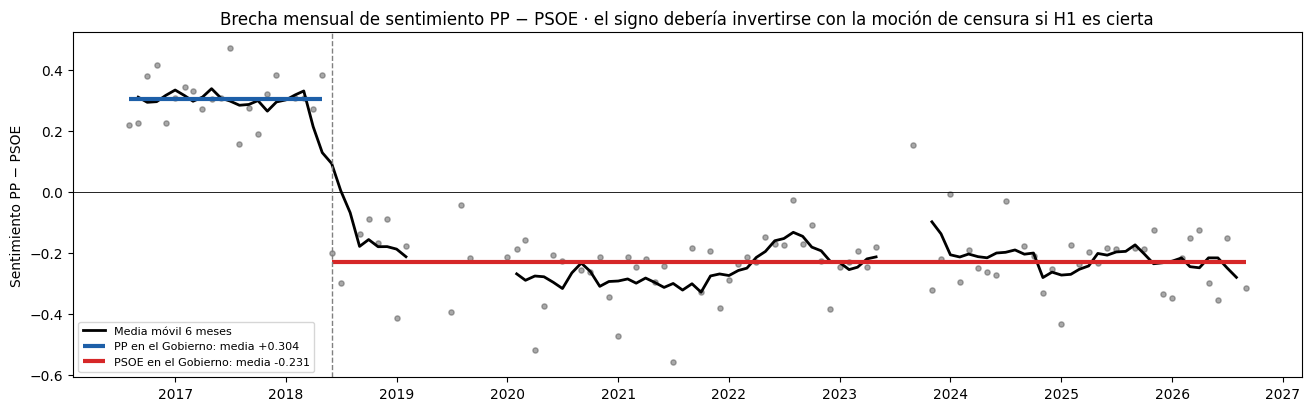

Meses con dato: antes 22, después 83


In [8]:
pv = panel.pivot(index="fecha", columns="party", values="sentiment").asfreq("MS")
brecha = (pv["PP"] - pv["PSOE"]).rename("brecha")
corte = pd.Timestamp("2018-06-01")
fig, ax = plt.subplots(figsize=(13, 4), layout="constrained")
ax.scatter(brecha.index, brecha, s=14, color="#555", alpha=.5)
ax.plot(brecha.index, media_movil(brecha), color="black", lw=2, label="Media móvil 6 meses")
for tramo, color, nombre in [(brecha[:corte - pd.Timedelta(days=1)], COLOR["PP"], "PP en el Gobierno"),
                             (brecha[corte:], COLOR["PSOE"], "PSOE en el Gobierno")]:
    ax.hlines(tramo.mean(), tramo.index.min(), tramo.index.max(), color=color, lw=3,
              label=f"{nombre}: media {tramo.mean():+.3f}")
ax.axhline(0, color="black", lw=.6); ax.axvline(corte, color="gray", ls="--", lw=1)
ax.set_ylabel("Sentimiento PP − PSOE")
ax.set_title("Brecha mensual de sentimiento PP − PSOE · el signo debería invertirse con la moción de censura si H1 es cierta")
ax.legend(fontsize=8, loc="lower left")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.savefig(RESULTS / "02_brecha_pp_psoe.png", dpi=160)
plt.show()
print(f"Meses con dato: antes {brecha[:corte].count()}, después {brecha[corte:].count()}")

## 6. Picos y valles

Un pico es un mes que se aparta de **su entorno**, no de la media de todo el periodo: si no, todos los meses positivos caerían en 2016–2017 solo por la tendencia. Por eso se mide la desviación de cada mes respecto a una media móvil centrada de 13 meses que lo excluye a él, y se estandariza (z).

- Solo se consideran meses con al menos 30 intervenciones, para no confundir un pico con el ruido de un mes con pocos datos.
- Un |z| > 2 se marca como candidato a anomalía. Es un umbral heurístico y no implica error ni causa.
- Para dar contexto sin inventarlo, se indica el **tópico LDA con mayor exceso** sobre su media en ese mes, a partir de las etiquetas de la Entrega 2.

In [9]:
labels = pd.read_csv(ROOT.parent / "corpus-indicators" / "reports" / "topic_labels.csv").set_index("topic").label
topics = list(labels.index)
s = glob.sentiment
suma = s.fillna(0).rolling(13, center=True, min_periods=1).sum() - s.fillna(0)
cuenta = s.notna().astype(int).rolling(13, center=True, min_periods=1).sum() - s.notna()
entorno = (suma / cuenta).where(cuenta >= 6)                  # media de los vecinos, sin el propio mes
fiable = glob.assign(entorno=entorno, desviacion=s - entorno)
fiable = fiable[(fiable.n_turns >= 30) & fiable.desviacion.notna()].copy()
fiable["z"] = (fiable.desviacion - fiable.desviacion.mean()) / fiable.desviacion.std()
exceso = fiable[topics] - glob[topics].mean()
fiable["topico_destacado"] = exceso.idxmax(axis=1).map(labels)
fiable["exceso_topico"] = exceso.max(axis=1)
picos = pd.concat([fiable.nsmallest(5, "z").assign(tipo="más negativo que su entorno"),
                   fiable.nlargest(5, "z").assign(tipo="más positivo que su entorno")])
picos = picos.reset_index()[["tipo", "month", "n_turns", "sentiment", "entorno", "desviacion", "z",
                             "topico_destacado", "exceso_topico"]]
print("Candidatos a anomalía (|z| > 2):", ", ".join(fiable.index[fiable.z.abs() > 2].strftime("%Y-%m")) or "ninguno")
picos.to_csv(RESULTS / "02_picos.csv", index=False)
picos.round(3)

Candidatos a anomalía (|z| > 2): 2016-11, 2017-06, 2018-11, 2020-07, 2024-02, 2024-07


,tipo,month,n_turns,sentiment,entorno,desviacion,z,topico_destacado,exceso_topico
0,más negativo que su entorno,2017-06,124,-0.278,-0.146,-0.132,-2.749,Corrupción y responsabilidad política,0.086
1,más negativo que su entorno,2018-11,89,-0.407,-0.306,-0.101,-2.099,Justicia y sistema constitucional,0.052
2,más negativo que su entorno,2024-02,123,-0.374,-0.273,-0.100,-2.093,"Infraestructuras, energía y sectores productivos",0.070
3,más negativo que su entorno,2020-05,68,-0.343,-0.255,-0.088,-1.833,Política europea e internacional,0.129
4,más negativo que su entorno,2025-05,164,-0.382,-0.315,-0.068,-1.415,Corrupción y responsabilidad política,0.061
5,más positivo que su entorno,2024-07,47,-0.175,-0.298,0.123,2.562,Justicia y sistema constitucional,0.130
6,más positivo que su entorno,2016-11,102,-0.059,-0.169,0.110,2.274,"Derechos sociales, igualdad y bienestar",0.062
7,más positivo que su entorno,2020-07,52,-0.171,-0.279,0.108,2.234,Política europea e internacional,0.177
8,más positivo que su entorno,2026-07,33,-0.262,-0.354,0.092,1.901,"Derechos sociales, igualdad y bienestar",0.098
9,más positivo que su entorno,2018-05,189,-0.180,-0.265,0.085,1.760,"Economía, fiscalidad y empleo",0.059


## 7. Estacionalidad

Con datos mensuales podría haber un patrón anual (por ejemplo, un tono distinto al inicio o al final de cada periodo de sesiones). Se mira de dos formas:
1. El **perfil por mes del año**: sentimiento medio de cada mes de calendario con su variabilidad entre años. Agosto solo tiene dato en 4 años (sesiones extraordinarias).
2. La **autocorrelación (ACF)** hasta 24 retardos: la estacionalidad anual se vería como picos en los retardos 12 y 24.

La ACF se calcula sin rellenar los huecos (`missing="conservative"`, que usa solo los pares de meses con dato).

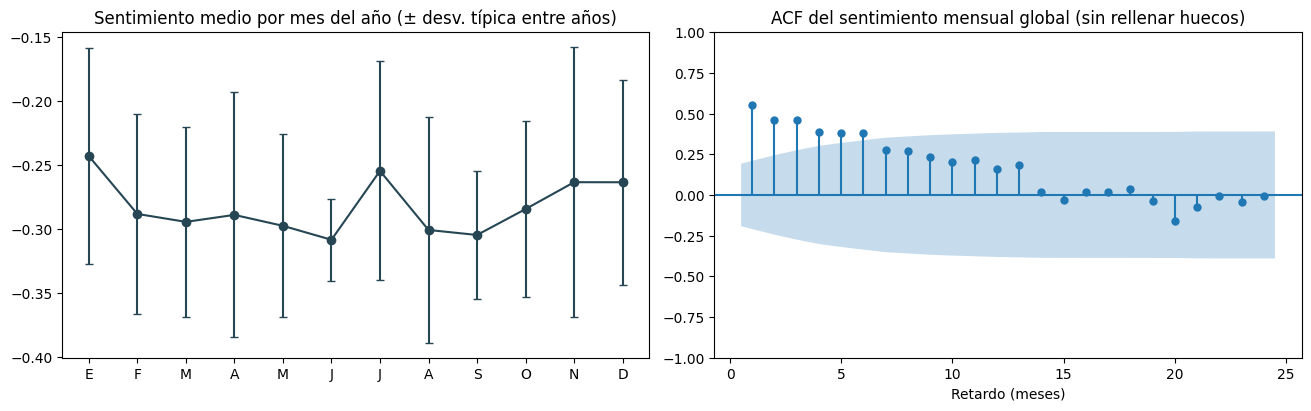

fecha     1       2      3      4      5      6      7      8       9      10     11     12
count  9.000  10.000  9.000  9.000  9.000  8.000  9.000  4.000  11.000  8.000  9.000  9.000
mean  -0.243  -0.288 -0.294 -0.289 -0.297 -0.308 -0.254 -0.301  -0.305 -0.284 -0.263 -0.263
std    0.085   0.078  0.074  0.096  0.072  0.032  0.085  0.088   0.050  0.069  0.106  0.080


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
perfil = glob.dropna(subset=["sentiment"]).groupby(glob.dropna(subset=["sentiment"]).index.month).sentiment
axes[0].errorbar(perfil.mean().index, perfil.mean(), yerr=perfil.std(), fmt="o-", capsize=3, color="#264653")
axes[0].set_xticks(range(1, 13), ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[0].set_title("Sentimiento medio por mes del año (± desv. típica entre años)")
plot_acf(glob.sentiment, lags=24, missing="conservative", zero=False, ax=axes[1])
axes[1].set_title("ACF del sentimiento mensual global (sin rellenar huecos)")
axes[1].set_xlabel("Retardo (meses)")
fig.savefig(RESULTS / "02_estacionalidad_acf.png", dpi=160)
plt.show()
print(perfil.agg(["count", "mean", "std"]).round(3).T.to_string())

## 8. Estacionariedad (ADF)

La prueba de Dickey-Fuller aumentada (ADF) contrasta H0: *la serie tiene raíz unitaria* (no es estacionaria). Un p < 0,05 permite rechazarla.

ADF no admite huecos, así que se aplica de dos formas y se comparan:
- **Sin los meses vacíos**, tratando los meses con dato como consecutivos.
- **Con interpolación lineal de los huecos.** Es una copia solo para este diagnóstico; no se usa para modelar.

Si ambas coinciden, la conclusión no depende de cómo se traten los huecos. Se prueba la serie en niveles y en primera diferencia, para la serie global y para los tres partidos con más cobertura. **En el notebook 03 se repetirá sobre el tramo de entrenamiento** para elegir la diferenciación `d`.

In [11]:
def adf(s):
    est, p, lags, n, *_ = adfuller(s, autolag="AIC", result_object=False)
    return est, p, n

series = {"Global": glob.sentiment}
series.update({p: pv[p] for p in ["PP", "PSOE", "Podemos-UP-Sumar"]})
filas = []
for nombre, s in series.items():
    s = s.loc[s.first_valid_index():s.last_valid_index()]
    for tratamiento, x in [("sin huecos", s.dropna()), ("interpolada", s.interpolate())]:
        for nivel, z in [("niveles", x), ("1ª diferencia", x.diff().dropna())]:
            est, p, n = adf(z)
            filas.append({"serie": nombre, "huecos": tratamiento, "transformación": nivel,
                          "ADF": est, "p_valor": p, "n": n, "¿estacionaria? (p<0,05)": "sí" if p < .05 else "no"})
adf_tabla = pd.DataFrame(filas)
adf_tabla.to_csv(RESULTS / "02_adf.csv", index=False)
adf_tabla.round(4)

,serie,huecos,transformación,ADF,p_valor,n,"¿estacionaria? (p<0,05)"
0,Global,sin huecos,niveles,-2.6397,0.0851,101,no
1,Global,sin huecos,1ª diferencia,-6.9970,0.0000,98,sí
2,Global,interpolada,niveles,-2.9297,0.0420,119,sí
3,Global,interpolada,1ª diferencia,-7.3717,0.0000,116,sí
4,PP,sin huecos,niveles,-1.8979,0.3331,101,no
5,PP,sin huecos,1ª diferencia,-12.1270,0.0000,101,sí
6,PP,interpolada,niveles,-2.4271,0.1342,118,no
7,PP,interpolada,1ª diferencia,-10.1144,0.0000,118,sí
8,PSOE,sin huecos,niveles,-2.2803,0.1784,98,no
9,PSOE,sin huecos,1ª diferencia,-7.9408,0.0000,98,sí


## 9. Resumen de la exploración

Las conclusiones concretas, con los valores obtenidos, se recogen en la explicación de este paso y se trasladarán a `analysis.md`. Lo que se lleva al notebook 03:
- **Las series que se modelan** y cómo se tratan los huecos: se dejan vacíos y SARIMAX los gestiona.
- **Si hace falta diferenciar o modelar la tendencia** (ADF).
- **Si tiene sentido un componente estacional** (perfil mensual y ACF en el retardo 12).
- **La magnitud del ruido mensual**, que limita la precisión que cabe esperar (MAE y RMSE).